In [19]:
## First import general packages for running python analysis:
import os, h5py, datetime,pytz,pickle, yaml, sys
import numpy as np
from matplotlib.pyplot import *
from matplotlib import pyplot as plt

## Then import the beamcals module:
sys.path.insert(0, '../../classes/')
import corr
import drone
import concat
import plotting_utils as pu
import fitting_utils as fu
import geometry_utils as gu
import time_utils as tu
import site_utils as si
import reduce as rc

# Define any channels, etc, and directories for this flight analysis

#config_directory="  "
maindir = '/hirax/DNS_freespace/2026_07_GBO/'
dronedir = maindir+'processed_flight_records/'
cdir = maindir+'TONE_crs_files/'
gdir = maindir+'TONE_crs_files/gains/' 

In [10]:
#Cell I used to define the coords originally, can ignore

# # Load the original configuration
# npz = np.load('../../metadata/GBO_DNS_config.npz', allow_pickle=True)
# config = {k: npz[k] for k in npz.files}

# # -------------------------------------------------------
# # Reorder channels
# # Old order:
# #   0 = Dish_5_X
# #   1 = Dish_5_Y
# #   2 = Dish_8_Y
# #   3 = Reference_channel
# #
# # New order:
# #   0 = Reference
# #   1 = BicoLOG
# #   2 = CHORD_NW
# #   3 = CHORD_NE
# # -------------------------------------------------------

# order = [3, 0, 1, 2]

# config["coords"] = config["coords"][order]
# config["pointings"] = config["pointings"][order]
# config["polarizations"] = config["polarizations"][order]

# # Rename channels
# config["keystrings"] = np.array([
#     "Reference",
#     "BicoLOG",
#     "CHORD_NW",
#     "CHORD_NE"
# ])

# # -------------------------------------------------------
# # Update coordinates
# # -------------------------------------------------------

# # Dish 5 coordinates (after reordering, these are rows 2 and 3)
# dish5_coords = config["coords"][2].copy()

# # 32 ft 8 in north = 9.9568 m
# north_offset_m = (32 + 8/12) * 0.3048

# # Reference stays NaN
# config["coords"][0] = np.array([np.nan, np.nan, np.nan])

# # BicoLOG = Dish 5 shifted north
# config["coords"][1] = dish5_coords.copy()
# config["coords"][1][1] += north_offset_m

# # CHORD_NW and CHORD_NE both use Dish 5 coordinates
# config["coords"][2] = dish5_coords.copy()
# config["coords"][3] = dish5_coords.copy()

# # -------------------------------------------------------
# # Save edited configuration
# # -------------------------------------------------------

# np.savez('../../metadata/GBO_DNS_CHORD_BICO_config.npz', **config)

# print("Saved new configuration to '../../metadata/GBO_DNS_CHORD_BICO_config.npz'")


# npz = np.load('../../metadata/GBO_DNS_CHORD_BICO_config.npz', allow_pickle=True)

# for key in ["keystrings", "coords"]:
#     print(f"\n--- {key} ---")
#     print(npz[key])

In [5]:
# whatever you want to call this dataset + _config (also used as the file name)
name = 'GBO_DNS_CHORD_BICO_config_test'

# 'crs' (ports 0-7) or 'ice' (ports 0-15); only used to check chmap
instrument = 'crs'

# total number of independent instruments measured
n_dishes = 3

# how many channels you actually made measurements with (that you care about)
n_channels = 4

# which ports of the 8 CRS (0-7) or 16 ICEBoard (0-15) ports did you use?
chmap = [0, 1, 2, 3]

# which dish index (0 .. n_dishes-1) each channel in chmap belongs to
chmap_to_dishes = [0, 1, 2, 2]

# what do you want to call the n_channels (in chmap order)?
keystrings = ['Reference', 'BicoLOG', 'CHORD_NW', 'CHORD_NE']

# reference point [lat, long, elevation]. With an origin, coords below are
# [East, North, Up] meters from it. Set origin = None to give each dish as
# [lat, long, elevation] instead.
origin = [38.42928, -79.84499, 810.]

# one row per dish, in dish order; nan row = location irrelevant
coords = [[np.nan, np.nan, np.nan],           # Reference
          [-16.47562334, 21.89848478, 0.],    # BicoLOG
          [-16.47562334, 11.94168478, 0.]]    # CHORD

# 'zenith' for every dish, or one per dish: 'zenith' or
# [degrees from zenith, azimuth in degrees East of North]
pointings = 'zenith'

# one per channel: degrees East of North, a compass name, or None
polarizations = [None, None, 'NW', 'NE']


#now actually create the file
site = si.make_site_file(name=name, instrument=instrument,
                                 n_dishes=n_dishes, n_channels=n_channels,
                                 chmap=chmap, chmap_to_dishes=chmap_to_dishes,
                                 keystrings=keystrings, origin=origin,
                                 coords=coords, pointings=pointings,
                                 polarizations=polarizations,save_path = '../../metadata/',
                                 overwrite=True)

Saved site file: ../../metadata/GBO_DNS_CHORD_BICO_config_test.npz
Site: GBO_DNS_CHORD_BICO_config_test
  file: ../../metadata/GBO_DNS_CHORD_BICO_config_test.npz   format: v2
  instrument: CRS
  origin: lat 38.429280, lon -79.844990, elev 810.0 m
  coords given as: East/North/Up metres from origin

Dishes / instruments (3):
  idx  name       channels            E (m)   N (m)  Up (m)  lat        lon         elev   given as  pointing
  ---  ---------  ------------------  ------  -----  ------  ---------  ----------  -----  --------  --------
  0    Reference  Reference           -       -      -       -          -           -      -         zenith  
  1    BicoLOG    BicoLOG             -16.48  21.90  0.00    38.429477  -79.845179  810.0  m         zenith  
  2    CHORD      CHORD_NW, CHORD_NE  -16.48  11.94  0.00    38.429388  -79.845179  810.0  m         zenith  

Channels (4):
  idx  keystring  port  dish           polarization
  ---  ---------  ----  -------------  ------------
  0  

In [6]:
#View or modify an existing site class file

gbosite = si.Site('../../metadata/GBO_DNS_CHORD_BICO_config_test.npz')             # load it 
gbosite.show()                                                                # print the dish + channel tables

# or, just to look without keeping an object:
si.show_site_file('../../metadata/GBO_DNS_CHORD_BICO_config_test.npz')

Site: GBO_DNS_CHORD_BICO_config_test
  file: ../../metadata/GBO_DNS_CHORD_BICO_config_test.npz   format: v2
  instrument: CRS
  origin: lat 38.429280, lon -79.844990, elev 810.0 m
  coords given as: East/North/Up metres from origin

Dishes / instruments (3):
  idx  name       channels            E (m)   N (m)  Up (m)  lat        lon         elev   given as  pointing
  ---  ---------  ------------------  ------  -----  ------  ---------  ----------  -----  --------  --------
  0    Reference  Reference           -       -      -       -          -           -      -         zenith  
  1    BicoLOG    BicoLOG             -16.48  21.90  0.00    38.429477  -79.845179  810.0  m         zenith  
  2    CHORD      CHORD_NW, CHORD_NE  -16.48  11.94  0.00    38.429388  -79.845179  810.0  m         zenith  

Channels (4):
  idx  keystring  port  dish           polarization
  ---  ---------  ----  -------------  ------------
  0    Reference  0     0 (Reference)  -           
  1    BicoLOG    1 

In [7]:
gbosite=si.Site('../../metadata/GBO_DNS_CHORD_BICO_config.npz')

In [11]:
#NWgrid + NEdrone BEST flight: 42dB atten, fixed LNAs
datadir = cdir + 'drone_flight9_NEgrid_NEpol_42db_jul2_2000/'
gaindir = gdir + '20260702-185855_gbo_gains_chord_path_drone_gridNWNE_Jul2_1900.npy'

#which cardinal direction were you copol with in this dataset?
copol = 'NE'
crosspol = 'NW'

#5 star spinning hover over TONE dish 8
flyfile= 'Jul-2nd-2026-07-59PM-Flight-Airdata.csv'

In [20]:
dronedata=drone.Drone_Data(Drone_Directory=dronedir,FLYTAG=flyfile,site_class=gbosite,tlb=0,tub=-1)

Initializing drone data via Airdata.csv routine: Jul-2nd-2026-07-59PM-Flight-Airdata.csv
  --> generating llh, geocentric cartesian, local cartesian, and local spherical coordinates.
  --> generating dish and receiver line of sight coordinates.


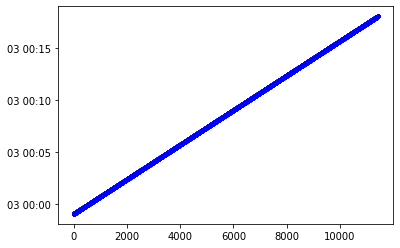

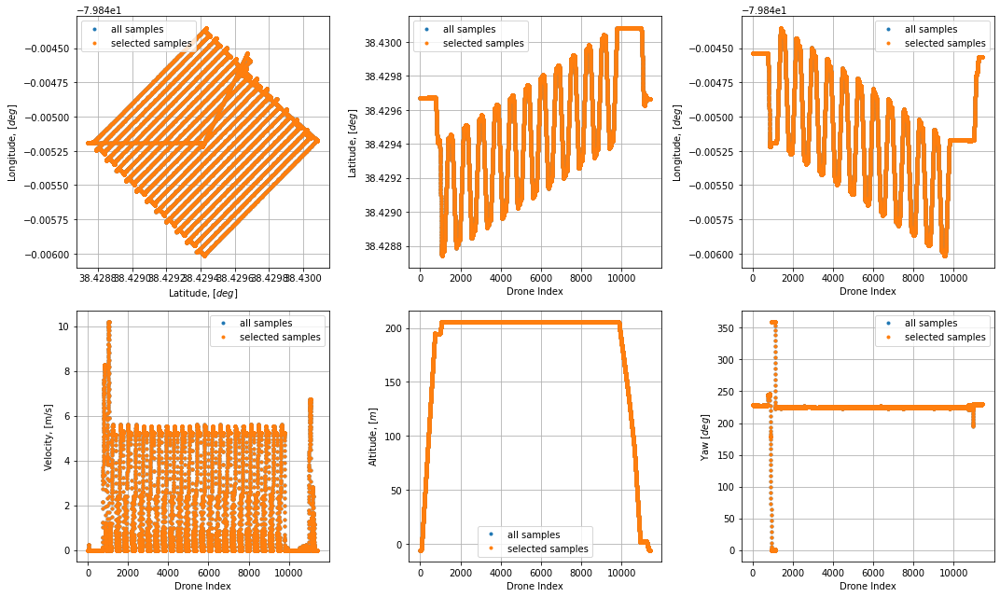

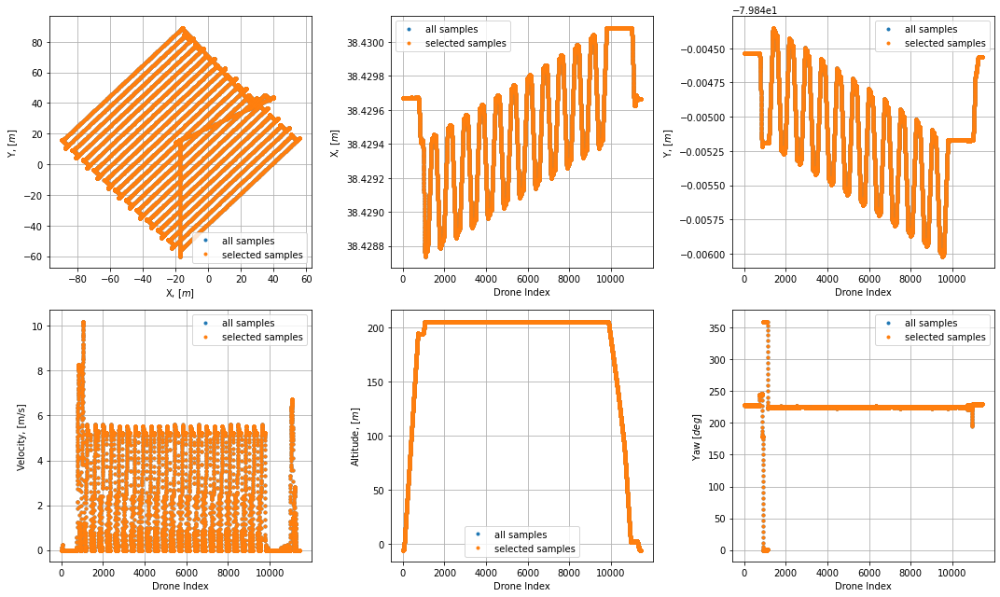

In [21]:
# Plot some drone data to get familiar with the coordinates in the drone class

# Look at time stamps
plt.plot(dronedata.t_arr_datetime,'b.',label='drone')
plt.show()


## Plot lat/long
fig1,[[ax1,ax2,ax3],[ax4,ax5,ax6]]=subplots(nrows=2,ncols=3,figsize=(15,9))
## Plot p0 coordinate origin:
ax1.plot(dronedata.origin[0],dronedata.origin[1],'ro')
ax2.axhline(dronedata.origin[0],c='b')
ax3.axhline(dronedata.origin[1],c='b')
## Title each coordinate subplot:        
ax1.set_title('Lat vs Lon')
ax2.set_title('Lat vs Time')
ax3.set_title('Lon vs Time')
ax4.set_title('Velocity vs Time')
ax5.set_title('Altitude vs Time')
ax6.set_title('Yaw vs Time')
## Specify arrays/vectors to plot in 1,3,4 coordinate subplot
xqtys=[dronedata.latitude,dronedata.t_index,dronedata.t_index,dronedata.t_index,dronedata.t_index,dronedata.t_index]
yqtys=[dronedata.longitude,dronedata.latitude,dronedata.longitude,dronedata.velocity,dronedata.altitude,dronedata.yaw]
xtags=['Latitude, [$deg$]','Drone Index','Drone Index','Drone Index','Drone Index','Drone Index']
ytags=['Longitude, [$deg$]','Latitude, [$deg$]','Longitude, [$deg$]','Velocity, [m/s]','Altitude, [$m$]','Yaw [$deg$]']
for i,ax in enumerate([ax1,ax2,ax3,ax4,ax5,ax6]):
    ax.plot(np.nanmin(xqtys[i]),np.nanmin(yqtys[i]))
    ax.plot(np.nanmax(xqtys[i]),np.nanmax(yqtys[i]))
    autoscalelims=ax.axis()
    ax.clear()
    ax.plot(xqtys[i],yqtys[i],'.',label='all samples')
    ax.plot(xqtys[i],yqtys[i],'.',label='selected samples')
    ax.set_xlabel(xtags[i])
    ax.set_ylabel(ytags[i])
    ax.grid()
    ax.legend()
    ax.set_xlim(autoscalelims[0],autoscalelims[1])
    ax.set_ylim(autoscalelims[2],autoscalelims[3])
tight_layout()
plt.show()

## Plot local X/Y coords
fig1,[[ax1,ax2,ax3],[ax4,ax5,ax6]]=subplots(nrows=2,ncols=3,figsize=(15,9))
## Plot p0 coordinate origin:
ax1.set_title('X vs Y')
ax2.set_title('X vs Time')
ax3.set_title('Y vs Time')
ax4.set_title('Velocity vs Time')
ax5.set_title('Altitude vs Time')
ax6.set_title('Yaw vs Time')
## Specify arrays/vectors to plot in 1,3,4 coordinate subplot
xqtys=[dronedata.coords_xyz_LC[:,0],dronedata.t_index,dronedata.t_index,dronedata.t_index,dronedata.t_index,dronedata.t_index]
yqtys=[dronedata.coords_xyz_LC[:,1],dronedata.latitude,dronedata.longitude,dronedata.velocity,dronedata.altitude,dronedata.yaw]
xtags=['X, [$m$]','Drone Index','Drone Index','Drone Index','Drone Index','Drone Index']
ytags=['Y, [$m$]','X, [$m$]','Y, [$m$]','Velocity, [m/s]','Altitude, [$m$]','Yaw [$deg$]']
for i,ax in enumerate([ax1,ax2,ax3,ax4,ax5,ax6]):
    ax.plot(np.nanmin(xqtys[i]),np.nanmin(yqtys[i]))
    ax.plot(np.nanmax(xqtys[i]),np.nanmax(yqtys[i]))
    autoscalelims=ax.axis()
    ax.clear()
    ax.plot(xqtys[i],yqtys[i],'.',label='all samples')
    ax.plot(xqtys[i],yqtys[i],'.',label='selected samples')
    ax.set_xlabel(xtags[i])
    ax.set_ylabel(ytags[i])
    ax.grid()
    ax.legend()
    ax.set_xlim(autoscalelims[0],autoscalelims[1])
    ax.set_ylim(autoscalelims[2],autoscalelims[3])
tight_layout()
plt.show()    

(1000, 8192, 36)
(1000,)
(1000,)
107.34831142425537
2026-07-03 00:00:44.071205
2026-07-03 00:02:31.419516
1783036844.071205


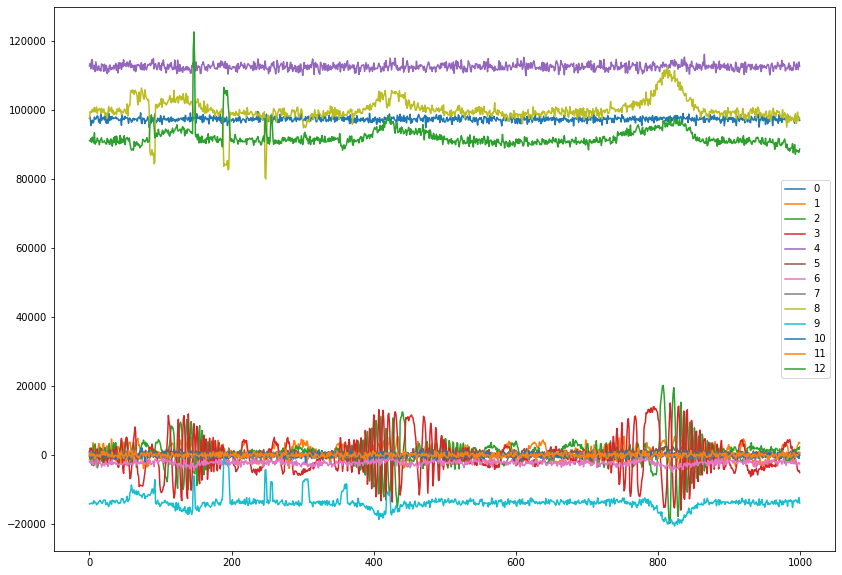

In [8]:
# (Optional:) Import a single file to get a better idea of which files you care about, if you identified the right 
# channel indices, etc. before importing the whole Corr_Data (can be very slow with large files)

fd=h5py.File(datadir+'7.hdf5', 'r')

fd.keys()
fd['index_map'].keys()

print(fd['vis'].shape) # time, freq, product
print(fd['counts'].shape)
print(fd['index_map']['time'].shape)

plt.figure(figsize=(14,10))
for i in np.arange(0,13):
    plt.plot(fd['vis'][:,f_ind,i].real,label=str(i)) # both real and imag are informative
plt.legend()
plt.plot()

t0 = fd['index_map']['time'][0]
t_end = fd['index_map']['time'][-1]

diff = t_end - t0
print(diff)

print(datetime.datetime.utcfromtimestamp(t0))
print(datetime.datetime.utcfromtimestamp(t_end))

print(fd['index_map']['time'][0])


In [16]:
#Load in the correlator data
corrdata=corr.Corr_Data(Data_Directory=datadir,
                        Gain_Directory=gaindir,site_class=gbosite,crs=True,fbounds=[0,8192],
                        Load_Gains=True,Apply_Gains=False,plot_offset_diagnostic=True,
                        Data_File_Index=None,offset_time_samples=100) 

TypeError: 'NoneType' object is not subscriptable

In [ ]:
# Save the entire object so you don't have to import again, highly recommended
# with open("/hirax/DNS_freespace/2026_07_GBO/analysis_outputs/corrdata_NEgNEp_GBO26.pkl", "wb") as f:
#     pickle.dump(corrdata,f,protocol=pickle.HIGHEST_PROTOCOL)


#Load it in if it already exists
# with open("/hirax/DNS_freespace/2026_07_GBO/analysis_outputs/corrdata_NEgNEp_GBO26.pkl", "rb") as f:
#     corrdata = pickle.load(f)

# print("Loaded synchronized corr object.")

(14000, 8192, 10)


(array([-250.,    0.,  250.,  500.,  750., 1000., 1250., 1500., 1750.,
        2000., 2250.]),
 [Text(-250.0, 0, '−250'),
  Text(0.0, 0, '0'),
  Text(250.0, 0, '250'),
  Text(500.0, 0, '500'),
  Text(750.0, 0, '750'),
  Text(1000.0, 0, '1000'),
  Text(1250.0, 0, '1250'),
  Text(1500.0, 0, '1500'),
  Text(1750.0, 0, '1750'),
  Text(2000.0, 0, '2000'),
  Text(2250.0, 0, '2250')])

<Figure size 2016x1800 with 0 Axes>

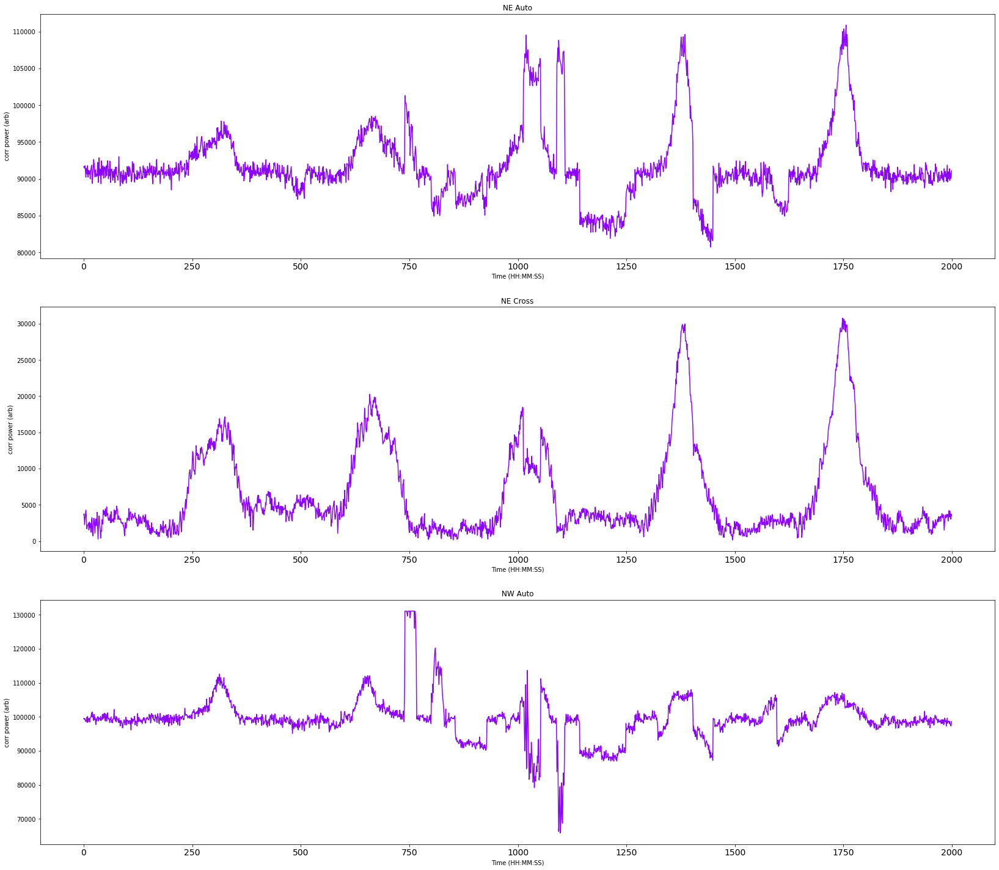

In [104]:
#(Optional) Displaying the magnitude of a few choice channels over time as a diagnostic check

from matplotlib import dates as mdates
pow_mag = get_mag_phase(abs(corrdata.V))



plt.figure(figsize=[28,25])
colorsarr=cm.gnuplot2(np.linspace(0,1,8192))
fbin=f_ind #3609
k=50
tmin,tmax=[7500,9500]
# Convert timestamps just once
times = corrdata.t_arr_datetime
times = times[tmin:tmax]  # apply slicing like the data

# Plot
plt.subplot(3,1,1)
plt.plot(pow_mag[tmin:tmax, fbin, 9], c=colorsarr[fbin])
plt.title(f"NE Auto")
plt.xlabel("Time (HH:MM:SS)")
plt.ylabel("corr power (arb)")
plt.xticks(fontsize=14)

plt.subplot(3,1,2)
plt.plot(pow_mag[tmin:tmax, fbin, 3], c=colorsarr[fbin])
plt.title(f"NE Cross")
plt.xlabel("Time (HH:MM:SS)")
plt.ylabel("corr power (arb)")
#plt.axvline(8550)
#plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
#plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=20))
plt.xticks(fontsize=14)

plt.subplot(3,1,3)
plt.plot(pow_mag[tmin:tmax, fbin, 7], c=colorsarr[fbin])
plt.title(f"NW Auto")
plt.xlabel("Time (HH:MM:SS)")
plt.ylabel("corr power (arb)")
#plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
#plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=20))
plt.xticks(fontsize=14)



In [28]:
def get_mag_phase(power0):
    """
    # return magnitude and phase in degrees of correlations
    """
    return np.absolute(power0), np.rad2deg(np.angle(power0))

pow_mag, pow_phase = get_mag_phase(corrdata.V)

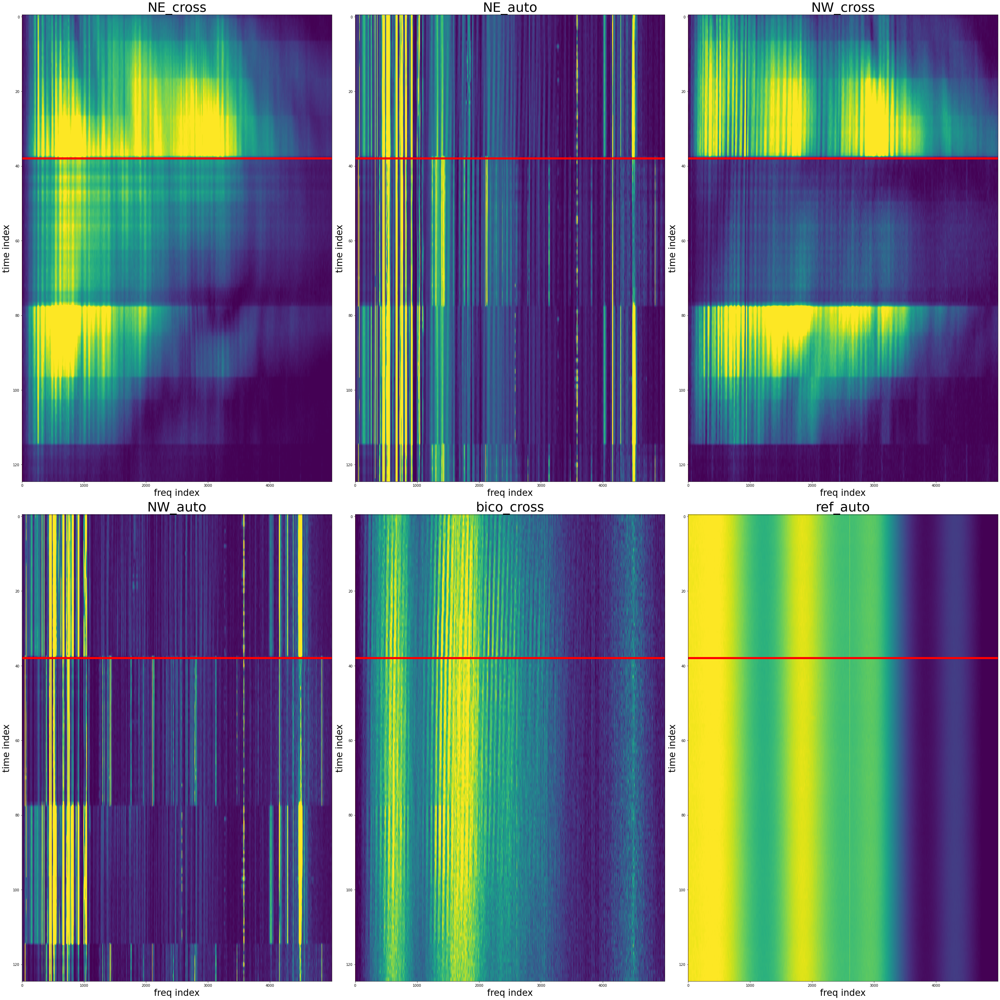

In [31]:
import math

def plot_waterfall_corr_data(data, corr_indices):
    plt.figure(figsize=(40, 40))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    for i,auto in enumerate(corr_indices):
        plt.subplot(dim1, dim2, i + 1)
        wfall = data[:, :, auto] # auto -> corr index
        
        plt.imshow(wfall, vmin = np.nanpercentile(wfall,5), vmax =np.nanpercentile(wfall,95), aspect='auto')
        plt.xlabel("freq index",fontsize='26')
        plt.ylabel("time index",fontsize='26')
        plt.axvline(1,c='red')
        plt.axhline(38,c='red',linewidth='6')
        plt.title(chnames[auto], fontsize='38')
    plt.tight_layout()


plot_waterfall_corr_data(pow_mag[8475:8600,2000:7000,:],[3,6,2,5,1,0])

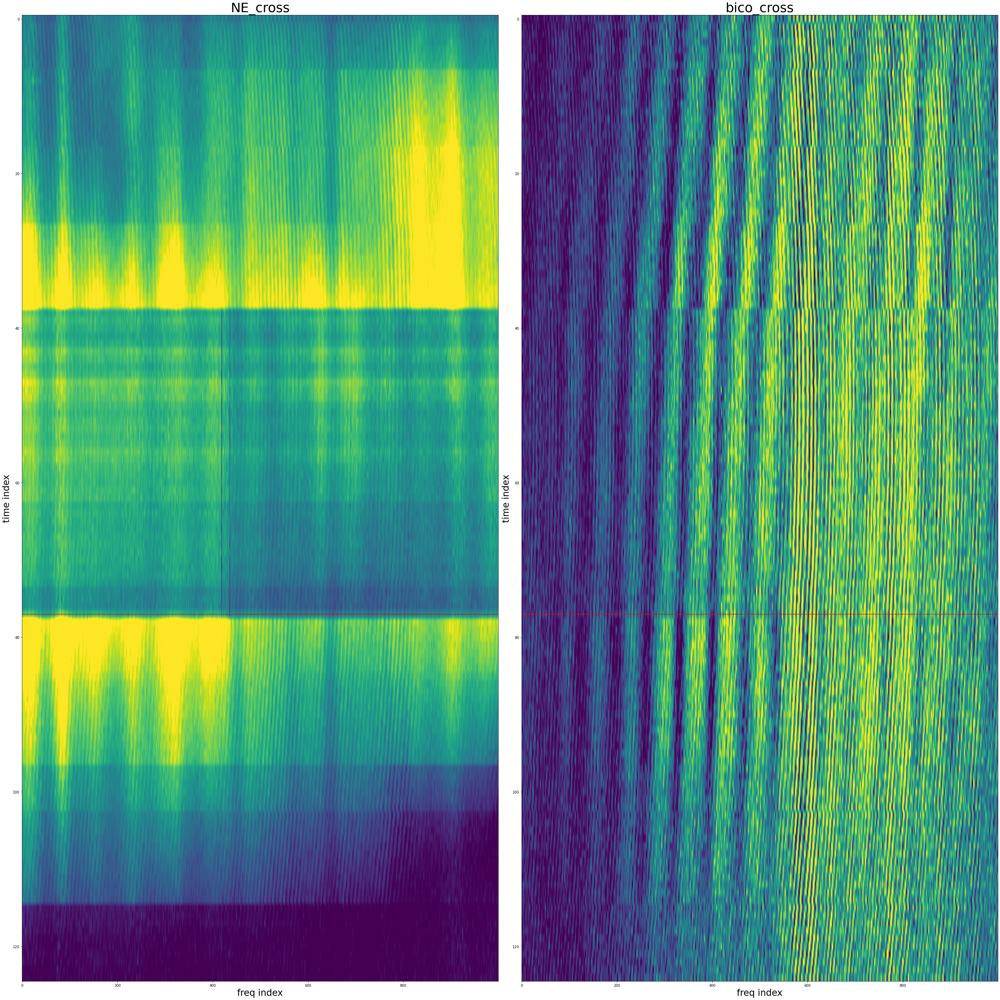

In [32]:
import math

def plot_waterfall_corr_data(data, corr_indices):
    plt.figure(figsize=(40, 40))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    for i,auto in enumerate(corr_indices):
        plt.subplot(dim1, dim2, i + 1)
        wfall = data[:, :, auto] # auto -> corr index
        
        plt.imshow(wfall, vmin = np.nanpercentile(wfall,5), vmax =np.nanpercentile(wfall,95), aspect='auto')
        plt.xlabel("freq index",fontsize='26')
        plt.ylabel("time index",fontsize='26')
        plt.axhline(77,c='red')
        #plt.axhline(37,c='red',linewidth='6')
        plt.title(chnames[auto], fontsize='38')
    plt.tight_layout()


plot_waterfall_corr_data(pow_mag[8475:8600,3000:4000,:],[3,1])

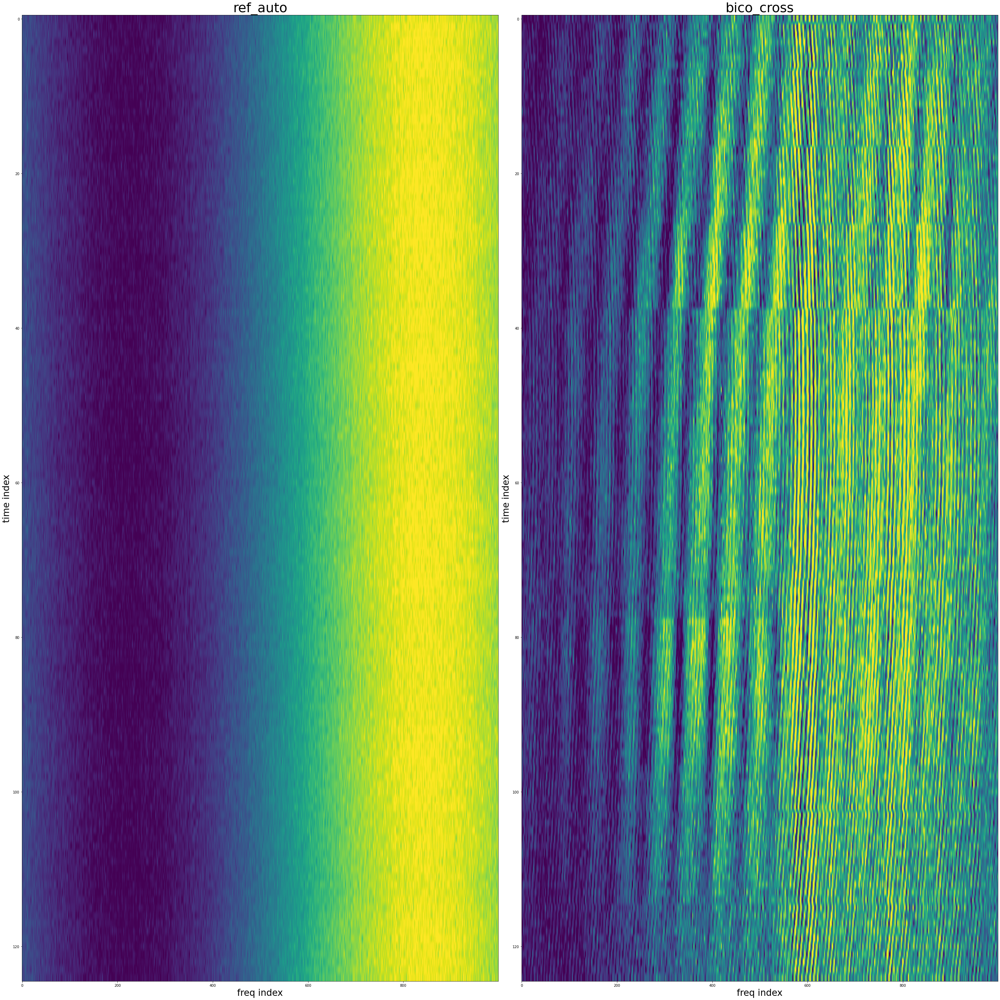

In [33]:
import math

def plot_waterfall_corr_data(data, corr_indices):
    plt.figure(figsize=(40, 40))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    for i,auto in enumerate(corr_indices):
        plt.subplot(dim1, dim2, i + 1)
        wfall = data[:, :, auto] # auto -> corr index
        
        plt.imshow(wfall, vmin = np.nanpercentile(wfall,5), vmax =np.nanpercentile(wfall,95), aspect='auto')
        plt.xlabel("freq index",fontsize='26')
        plt.ylabel("time index",fontsize='26')
        #plt.axhline(77,c='red',linewidth='6')
        #plt.axhline(37,c='red',linewidth='6')
        plt.title(chnames[auto], fontsize='38')
    plt.tight_layout()


plot_waterfall_corr_data(pow_mag[8475:8600,3000:4000,:],[0,1])#8600

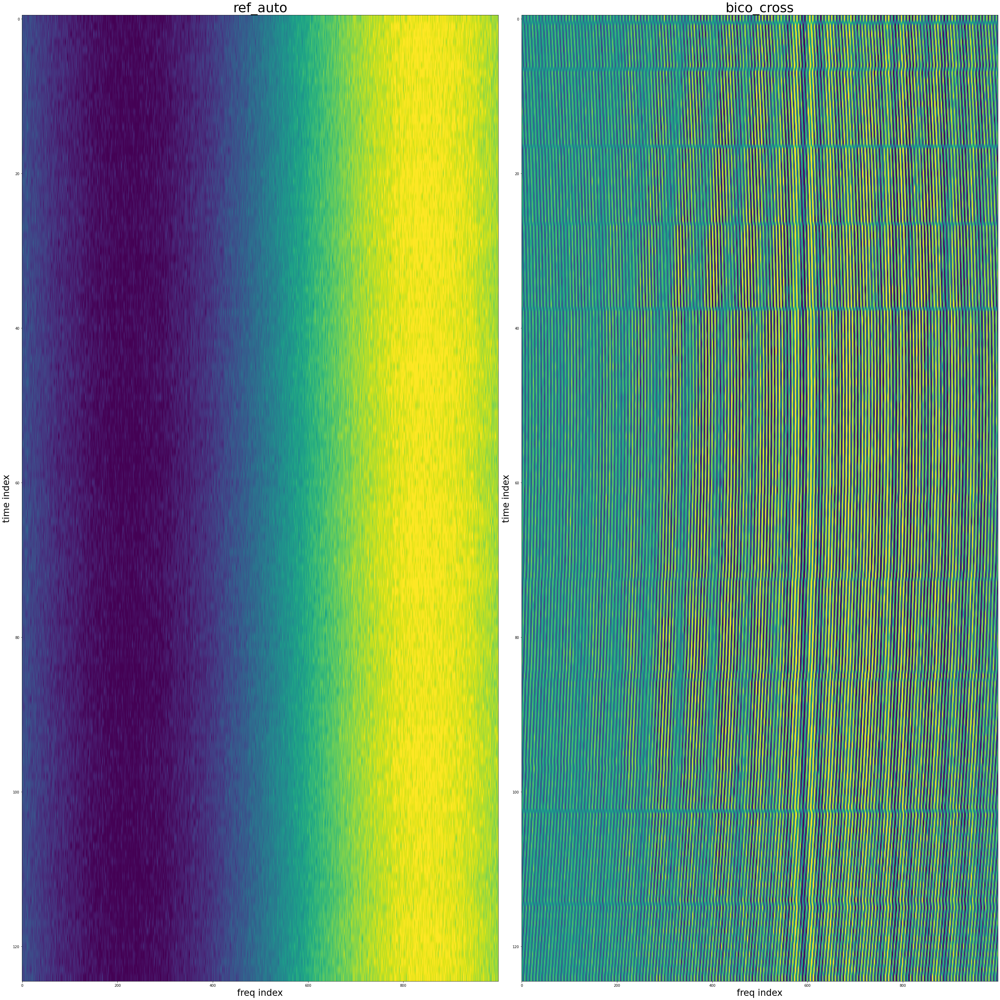

In [37]:
import math

def plot_waterfall_corr_data(data, corr_indices):
    plt.figure(figsize=(40, 40))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    for i,auto in enumerate(corr_indices):
        plt.subplot(dim1, dim2, i + 1)
        wfall = data[:, :, auto] # auto -> corr index
        
        plt.imshow(wfall, vmin = np.nanpercentile(wfall,5), vmax =np.nanpercentile(wfall,95), aspect='auto')
        plt.xlabel("freq index",fontsize='26')
        plt.ylabel("time index",fontsize='26')
        #plt.axhline(77,c='red',linewidth='6')
        #plt.axhline(37,c='red',linewidth='6')
        plt.title(chnames[auto], fontsize='38')
    plt.tight_layout()


plot_waterfall_corr_data(corrdata.V.real[8475:8600,3000:4000,:],[0,1])#8600

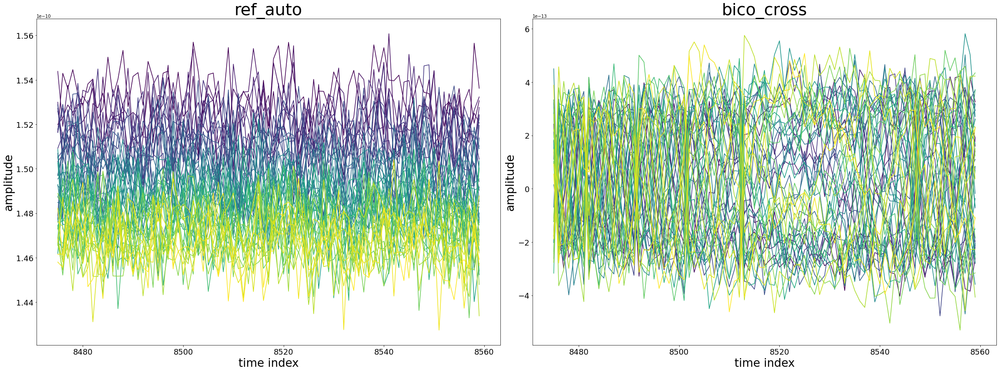

In [50]:
import math
import numpy as np
import matplotlib.pyplot as plt

def plot_freq_lines_corr_data(data, corr_indices, freq_range, n_freqs, time_range=None):
    """
    data: array shaped (time, freq, channel)
    corr_indices: list of channel/corr indices (axis 2)
    freq_range: (f_start, f_stop) in absolute freq indices (stop exclusive)
    n_freqs: how many frequencies to plot, evenly spaced across freq_range
    time_range: optional (t_start, t_stop) in absolute time indices
    """
    t0, t1 = time_range if time_range is not None else (0, data.shape[0])
    f0, f1 = freq_range
    freqs = np.unique(np.linspace(f0, f1 - 1, n_freqs).astype(int))
    t = np.arange(t0, t1)
    colors = plt.cm.viridis(np.linspace(0, 1, len(freqs)))

    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices) / dim1)
    plt.figure(figsize=(16 * dim2, 12 * dim1))

    for i, auto in enumerate(corr_indices):
        plt.subplot(dim1, dim2, i + 1)
        for f, c in zip(freqs, colors):
            plt.plot(t, data[t0:t1, f, auto], color=c, label=f"freq {f}")
        plt.xlabel("time index", fontsize=26)
        plt.ylabel("amplitude", fontsize=26)
        plt.title(chnames[auto], fontsize=38)
        plt.tick_params(labelsize=18)
        #plt.legend(fontsize=16, ncol=max(1, len(freqs) // 10))
    plt.tight_layout()


plot_freq_lines_corr_data(corrdata.V.real, [0, 1],
                          freq_range=(3000, 3200), n_freqs=50,
                          time_range=(8475, 8560))

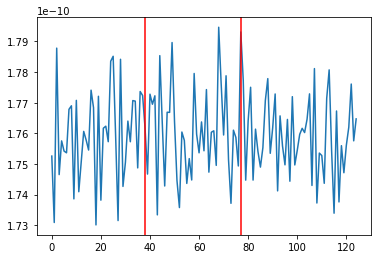

In [118]:
#plt.plot(pow_mag[8475:8600,6500,0])
plt.plot(pow_mag[8475:8600,2000,0])
plt.axvline(38,c='red')
plt.axvline(77,c='red')

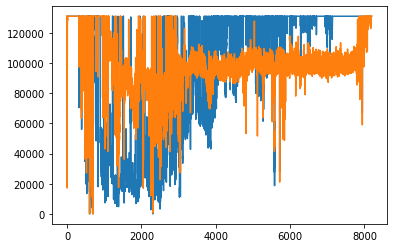

In [51]:
plt.plot(pow_mag[8525,:,5])
plt.plot(pow_mag[8500,:,5])

In [16]:
corrdata.freq[4500]

878.90625

In [105]:
concatdata=concat.CONCAT(CORRDATCLASS=corrdata,DRONEDATCLASS=dronedata,\
                             load_yaml=False,traceback=False,save_traceback=False,t_drone_offset=0)

In [106]:
for j in np.arange(0,len(crmap)):
    plt.scatter(concatdata.drone_xyz_LC_interp[:,0],concatdata.drone_xyz_LC_interp[:,1],c=np.abs(concatdata.V_cross[:,f_ind,j]))
    plt.colorbar()
    plt.xlabel('X [m]')
    plt.ylabel('Y [m]')
    plt.title(chnames[j])
    plt.show()

AttributeError: 'CONCAT' object has no attribute 'V_cross'

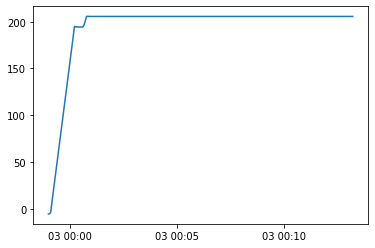

In [67]:
plt.plot(concatdata.t_arr_datetime,concatdata.drone_xyz_LC_interp[:,2],label='drone')

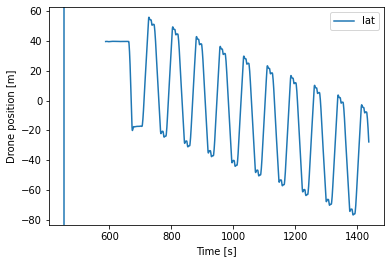

In [68]:
t_seconds = np.array([
    (t - concatdata.t_arr_datetime[0]).total_seconds()
    for t in concatdata.t_arr_datetime
])

plt.plot(t_seconds, concatdata.drone_xyz_LC_interp[:,0], label='lat')
plt.xlabel('Time [s]')
plt.ylabel('Drone position [m]')
plt.axvline(455)
#plt.xlim(460,515)
plt.legend()
plt.show()

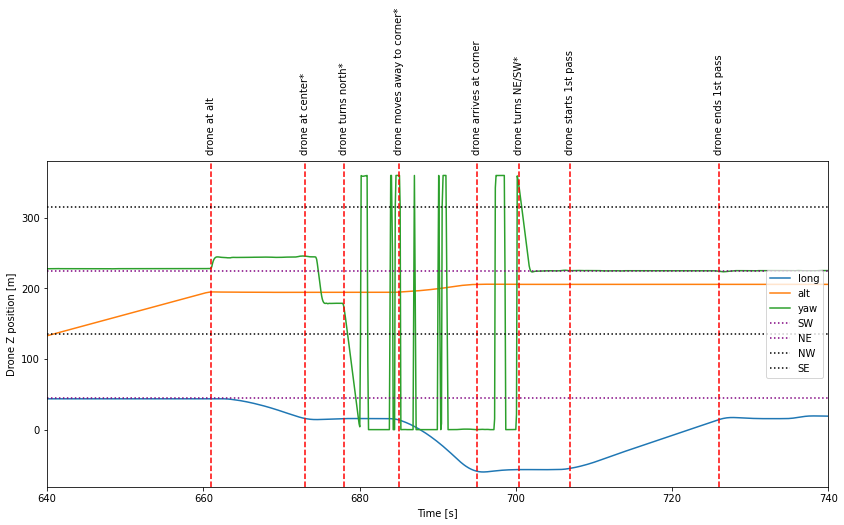

In [69]:
t_seconds = np.array([
    (t - concatdata.t_arr_datetime[0]).total_seconds()
    for t in concatdata.t_arr_datetime
])

plt.figure(figsize=(14,6))
plt.plot(t_seconds, concatdata.drone_xyz_LC_interp[:,1], label='long')
plt.plot(t_seconds, concatdata.drone_xyz_LC_interp[:,2], label='alt')
plt.plot(t_seconds, concatdata.drone_yaw_interp[:], label='yaw')
plt.xlabel('Time [s]')
plt.ylabel('Drone Z position [m]')

plt.axvline(661, color='red', linestyle='--')
plt.text(
    661,
    1.02,                     # just above the axes
    'drone at alt',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)


plt.axvline(673, color='red', linestyle='--')
plt.text(
    673,
    1.02,                     # just above the axes
    'drone at center*',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)


plt.axvline(678, color='red', linestyle='--')
plt.text(
    678,
    1.02,                     # just above the axes
    'drone turns north*',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)

plt.axvline(685, color='red', linestyle='--')
plt.text(
    685,
    1.02,                     # just above the axes
    'drone moves away to corner*',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)

plt.axvline(695, color='red', linestyle='--')
plt.text(
    695,
    1.02,                     # just above the axes
    'drone arrives at corner',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)


plt.axvline(700.4, color='red', linestyle='--')
plt.text(
    700.4,
    1.02,                     # just above the axes
    'drone turns NE/SW*',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)


plt.axvline(707, color='red', linestyle='--')
plt.text(
    707,
    1.02,                     # just above the axes
    'drone starts 1st pass',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)

plt.axvline(726, color='red', linestyle='--')
plt.text(
    726,
    1.02,                     # just above the axes
    'drone ends 1st pass',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)

plt.axhline(225, label='SW',c='purple',linestyle=':')
plt.axhline(45, label='NE',c='purple',linestyle=':')
plt.axhline(315, label='NW',c='black',linestyle=':')
plt.axhline(135, label='SE',c='black',linestyle=':')
plt.xlim(640,740)
plt.legend(loc='right')
plt.show()

In [70]:
685-707

-22

In [71]:
432-5-33

394

In [72]:
232.25-5.4

226.85

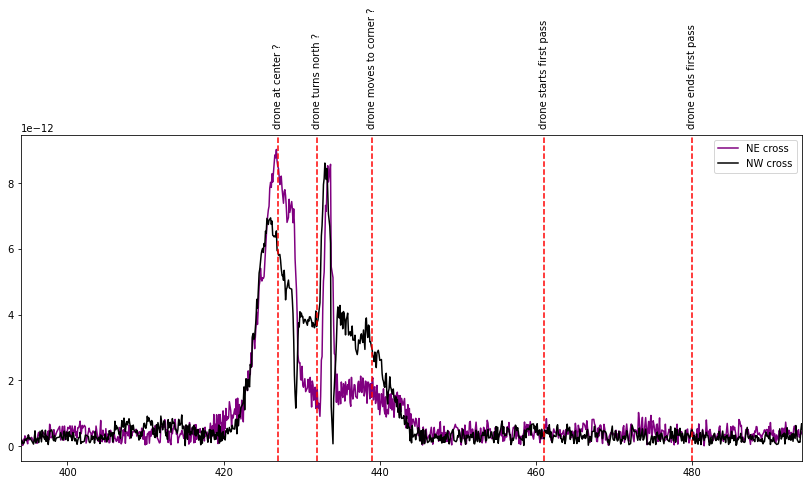

In [74]:
plt.figure(figsize=(14,6))
plt.plot(t_seconds,abs(concatdata.V[:,f_ind,3]),label='NE cross',c='purple')
plt.plot(t_seconds,abs(concatdata.V[:,f_ind,2]),label='NW cross',c='black')

plt.axvline(432-5, color='red', linestyle='--')
plt.text(
    432-5,
    1.02,                     # just above the axes
    'drone at center ?',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)


plt.axvline(432, color='red', linestyle='--')
plt.text(
    432,
    1.02,                     # just above the axes
    'drone turns north ?',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)

plt.axvline(432+7, color='red', linestyle='--')
plt.text(
    432+7,
    1.02,                     # just above the axes
    'drone moves to corner ?',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)


plt.axvline(432+7+22, color='red', linestyle='--')
plt.text(
    432+7+22,
    1.02,                     # just above the axes
    'drone starts first pass',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)

plt.axvline(432+7+22+19, color='red', linestyle='--')
plt.text(
    432+7+22+19,
    1.02,                     # just above the axes
    'drone ends first pass',
    rotation=90,
    ha='center',
    va='bottom',
    transform=plt.gca().get_xaxis_transform()
)

plt.xlim(394,494)
plt.legend()

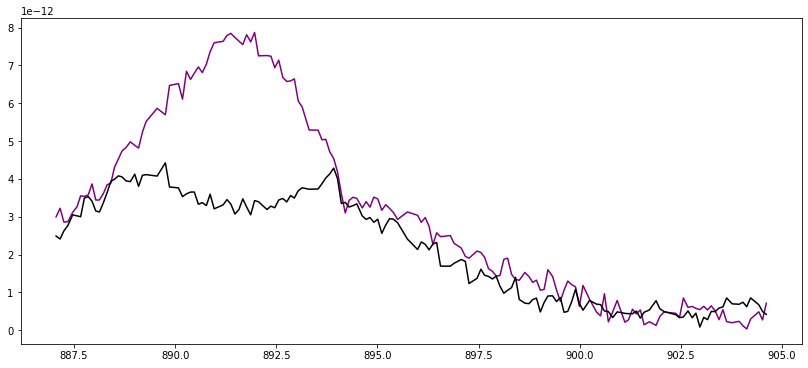

In [77]:
plt.figure(figsize=(14,6))
plt.plot(t_seconds[8840:9000],abs(concatdata.V[8840:9000,f_ind,3]),label='NE cross',c='purple')
plt.plot(t_seconds[8840:9000],abs(concatdata.V[8840:9000,f_ind,2]),label='NW cross',c='black')



In [81]:
432-678

-246

In [11]:
concatdata_mtc=concat.CONCAT(CORRDATCLASS=corrdata,DRONEDATCLASS=dronedata,\
                             load_yaml=False,traceback=False,save_traceback=False,t_drone_offset=-245.8)

#push down:-246.1
#push up:-245.5
#fine params = [-0.4,0.4,.0001]

Created drone_pitch_interp
Filled drone_pitch_interp


In [97]:
(-246.1-245.5)/2

-245.8

In [98]:
246.1-245.8

0.29999999999998295

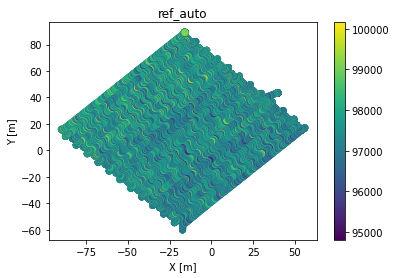

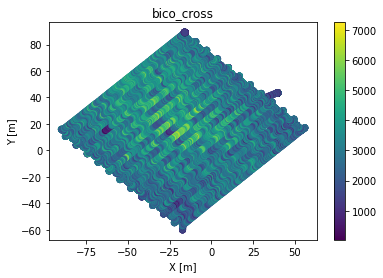

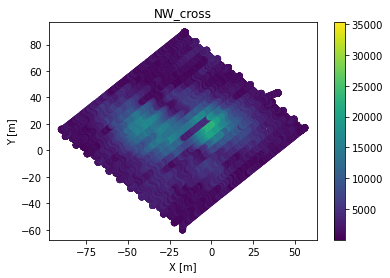

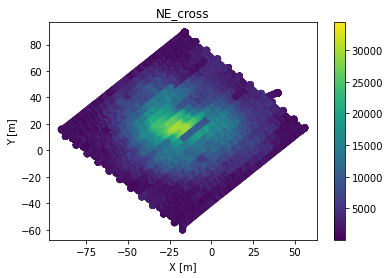

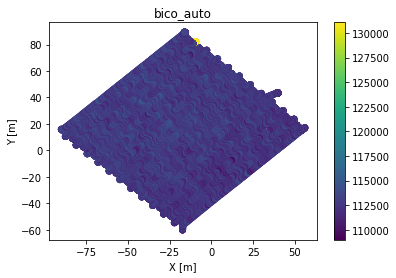

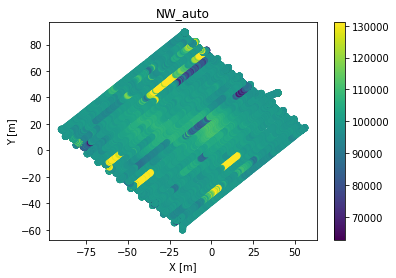

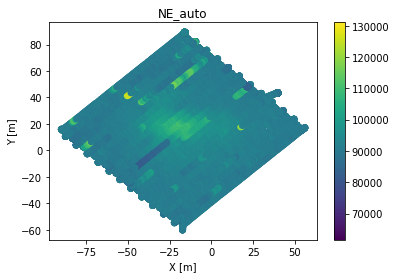

In [99]:
for j in np.arange(0,len(crmap)):
    plt.scatter(concatdata_mtc.drone_xyz_LC_interp[:,0],concatdata_mtc.drone_xyz_LC_interp[:,1],c=np.abs(concatdata_mtc.V_cross[:,f_ind,j]))
    plt.colorbar()
    plt.xlabel('X [m]')
    plt.ylabel('Y [m]')
    plt.title(chnames[j])
    plt.show()

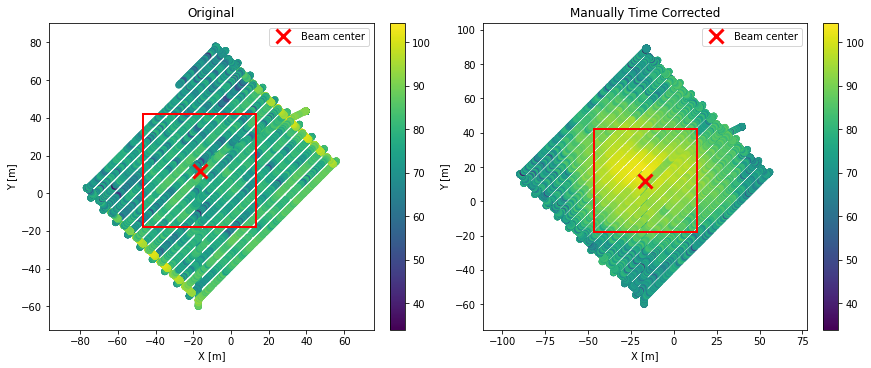

In [12]:
from matplotlib.patches import Rectangle

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

chan = 3
box_size = 60  # meters (adjust as desired)

# Compute values once
c1 = 10*np.log(np.abs(concatdata.V_cross[:, f_ind, chan]))
c2 = 10*np.log(np.abs(concatdata_mtc.V_cross[:, f_ind, chan]))

# Use a common color scale
vmin = min(np.nanmin(c1), np.nanmin(c2))
vmax = max(np.nanmax(c1), np.nanmax(c2))

# Beam center from site class
x0 = concatdata.dish_coords[chan, 0]
y0 = concatdata.dish_coords[chan, 1]

# Left plot
sc1 = ax1.scatter(
    concatdata.drone_xyz_LC_interp[:,0],
    concatdata.drone_xyz_LC_interp[:,1],
    c=c1,
    vmin=vmin,
    vmax=vmax
)

ax1.plot(x0, y0, 'rx', markersize=14, markeredgewidth=3, label='Beam center')
ax1.add_patch(Rectangle(
    (x0 - box_size/2, y0 - box_size/2),
    box_size,
    box_size,
    fill=False,
    edgecolor='red',
    linewidth=2
))

ax1.set_title("Original")
ax1.set_xlabel("X [m]")
ax1.set_ylabel("Y [m]")
ax1.axis('equal')
ax1.legend()
fig.colorbar(sc1, ax=ax1)

# Right plot
sc2 = ax2.scatter(
    concatdata_mtc.drone_xyz_LC_interp[:,0],
    concatdata_mtc.drone_xyz_LC_interp[:,1],
    c=c2,
    vmin=vmin,
    vmax=vmax
)

ax2.plot(x0, y0, 'rx', markersize=14, markeredgewidth=3, label='Beam center')
ax2.add_patch(Rectangle(
    (x0 - box_size/2, y0 - box_size/2),
    box_size,
    box_size,
    fill=False,
    edgecolor='red',
    linewidth=2
))

ax2.set_title("Manually Time Corrected")
ax2.set_xlabel("X [m]")
ax2.set_ylabel("Y [m]")
ax2.axis('equal')
ax2.legend()
fig.colorbar(sc2, ax=ax2)

plt.show()

In [105]:
concatdata_mtc.Synchronization_Function(
    inputcorr=corrdata,
    inputdrone=dronedata,
    coarse_params=[-245.8-15, -245.8+15, 1],
    fine_params=[-0.5, 0.5, 0.0005],
    FMB_coordbounds=[60.0, 60.0, 180.0],
    freqs=np.arange(3300,3600,30),
    FMB_ampbound=1,
    chans=np.array([3])
)

Coarse search:   0%|          | 0/30 [00:00<?, ?it/s]

Created drone_pitch_interp
Filled drone_pitch_interp


/home/mlc253/anaconda3/lib/python3.8/site-packages/scipy/stats/_stats_py.py:4424: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(msg))


Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_

/home/mlc253/anaconda3/lib/python3.8/site-packages/scipy/stats/_stats_py.py:4461: NearConstantInputWarning: An input array is nearly constant; the computed correlation coefficient may be inaccurate.
  warnings.warn(stats.NearConstantInputWarning(msg))


Fine search:   0%|          | 0/2000 [00:00<?, ?it/s]

... (9 outputs left out)

Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_

Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_

Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_

Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_interp
Created drone_pitch_interp
Filled drone_pitch_

In [106]:
concatdata_mtc.t_delta_dji

-245.75650000001286

In [13]:
concatdata_ctc=concat.CONCAT(CORRDATCLASS=corrdata,DRONEDATCLASS=dronedata,
                             load_yaml=False,traceback=False,save_traceback=False,t_drone_offset=-245.7565)

Created drone_pitch_interp
Filled drone_pitch_interp


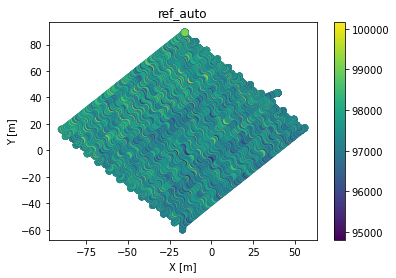

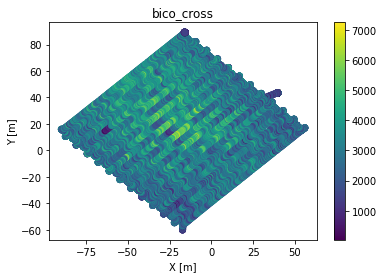

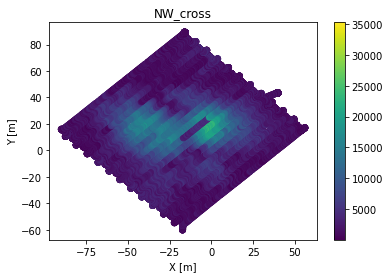

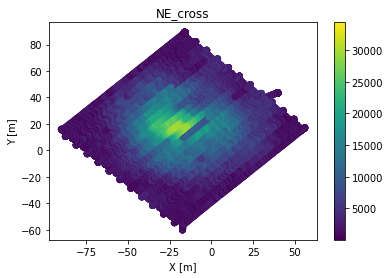

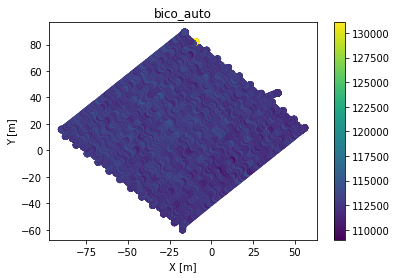

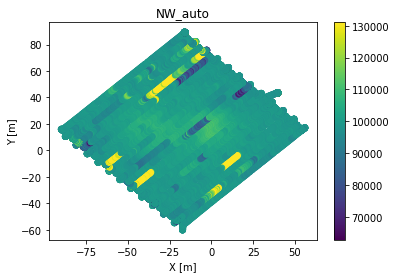

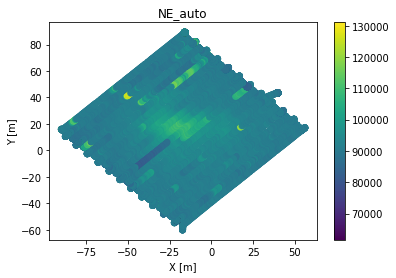

In [14]:
for j in np.arange(0,len(crmap)):
    plt.scatter(concatdata_ctc.drone_xyz_LC_interp[:,0],concatdata_ctc.drone_xyz_LC_interp[:,1],c=np.abs(concatdata_ctc.V_cross[:,f_ind,j]))
    plt.colorbar()
    plt.xlabel('X [m]')
    plt.ylabel('Y [m]')
    plt.title(chnames[j])
    plt.show()

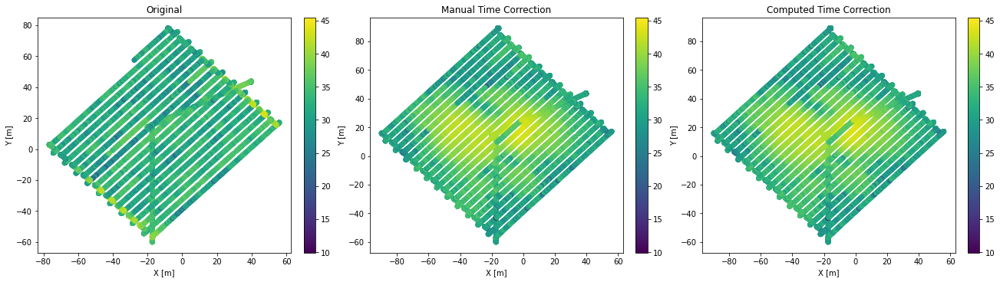

In [15]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

chan = 2

# Compute values once
c1 = 10*np.log10(np.abs(concatdata.V_cross[:, f_ind, chan]))
c2 = 10*np.log10(np.abs(concatdata_mtc.V_cross[:, f_ind, chan]))
c3 = 10*np.log10(np.abs(concatdata_ctc.V_cross[:, f_ind, chan]))

# Use a common color scale
vmin = min(np.nanmin(c1), np.nanmin(c2), np.nanmin(c3))
vmax = max(np.nanmax(c1), np.nanmax(c2), np.nanmax(c3))

# Original
sc1 = ax1.scatter(
    concatdata.drone_xyz_LC_interp[:, 0],
    concatdata.drone_xyz_LC_interp[:, 1],
    c=c1,
    vmin=vmin,
    vmax=vmax
)
ax1.set_title("Original")
ax1.set_xlabel("X [m]")
ax1.set_ylabel("Y [m]")
fig.colorbar(sc1, ax=ax1)

# Time Corrected
sc2 = ax2.scatter(
    concatdata_mtc.drone_xyz_LC_interp[:, 0],
    concatdata_mtc.drone_xyz_LC_interp[:, 1],
    c=c2,
    vmin=vmin,
    vmax=vmax
)
ax2.set_title("Manual Time Correction")
ax2.set_xlabel("X [m]")
ax2.set_ylabel("Y [m]")
fig.colorbar(sc2, ax=ax2)

# Additional Time Corrected
sc3 = ax3.scatter(
    concatdata_ctc.drone_xyz_LC_interp[:, 0],
    concatdata_ctc.drone_xyz_LC_interp[:, 1],
    c=c3,
    vmin=vmin,
    vmax=vmax
)
ax3.set_title("Computed Time Correction")
ax3.set_xlabel("X [m]")
ax3.set_ylabel("Y [m]")
fig.colorbar(sc3, ax=ax3)

plt.show()

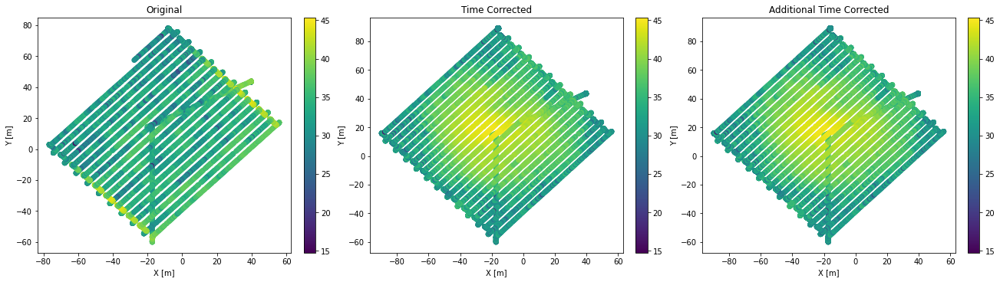

In [16]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

chan = 3

# Compute values once
c1 = 10*np.log10(np.abs(concatdata.V_cross[:, f_ind, chan]))
c2 = 10*np.log10(np.abs(concatdata_mtc.V_cross[:, f_ind, chan]))
c3 = 10*np.log10(np.abs(concatdata_ctc.V_cross[:, f_ind, chan]))

# Use a common color scale
vmin = min(np.nanmin(c1), np.nanmin(c2), np.nanmin(c3))
vmax = max(np.nanmax(c1), np.nanmax(c2), np.nanmax(c3))

# Original
sc1 = ax1.scatter(
    concatdata.drone_xyz_LC_interp[:, 0],
    concatdata.drone_xyz_LC_interp[:, 1],
    c=c1,
    vmin=vmin,
    vmax=vmax
)
ax1.set_title("Original")
ax1.set_xlabel("X [m]")
ax1.set_ylabel("Y [m]")
fig.colorbar(sc1, ax=ax1)

# Time Corrected
sc2 = ax2.scatter(
    concatdata_mtc.drone_xyz_LC_interp[:, 0],
    concatdata_mtc.drone_xyz_LC_interp[:, 1],
    c=c2,
    vmin=vmin,
    vmax=vmax
)
ax2.set_title("Time Corrected")
ax2.set_xlabel("X [m]")
ax2.set_ylabel("Y [m]")
fig.colorbar(sc2, ax=ax2)

# Additional Time Corrected
sc3 = ax3.scatter(
    concatdata_ctc.drone_xyz_LC_interp[:, 0],
    concatdata_ctc.drone_xyz_LC_interp[:, 1],
    c=c3,
    vmin=vmin,
    vmax=vmax
)
ax3.set_title("Additional Time Corrected")
ax3.set_xlabel("X [m]")
ax3.set_ylabel("Y [m]")
fig.colorbar(sc3, ax=ax3)

plt.show()

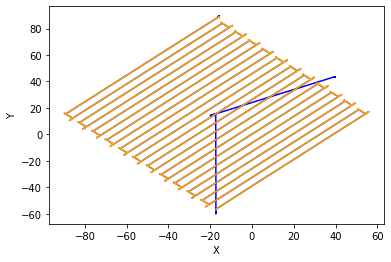

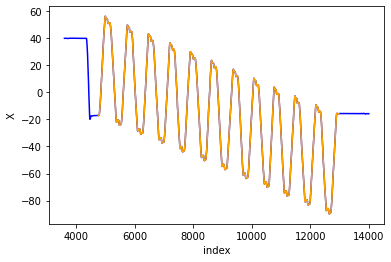

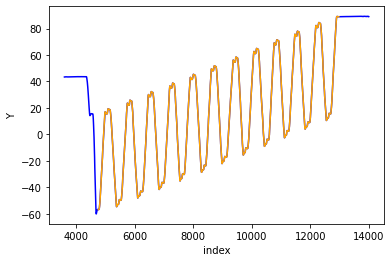

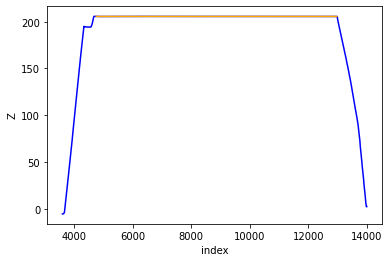

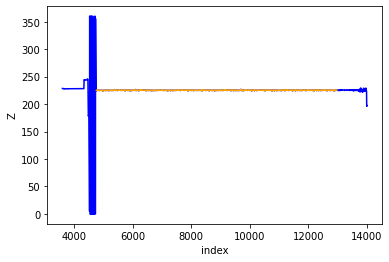

In [26]:
# Let's pick most interesting drone data region

tlb = 4750
tub = 12975
indrange = np.arange(tlb,tub)


plt.plot(concatdata_ctc.drone_xyz_LC_interp[:,0],concatdata_ctc.drone_xyz_LC_interp[:,1],color='blue')
plt.plot(concatdata_ctc.drone_xyz_LC_interp[tlb:tub,0],concatdata_ctc.drone_xyz_LC_interp[tlb:tub,1],color='orange')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

plt.plot(concatdata_ctc.drone_xyz_LC_interp[:,0],color='blue')
plt.plot(indrange,concatdata_ctc.drone_xyz_LC_interp[tlb:tub,0],color='orange')
plt.xlabel('index')
plt.ylabel('X')
plt.show()

plt.plot(concatdata_ctc.drone_xyz_LC_interp[:,1],color='blue')
plt.plot(indrange,concatdata_ctc.drone_xyz_LC_interp[tlb:tub,1],color='orange')
plt.xlabel('index')
plt.ylabel('Y')
plt.show()

plt.plot(concatdata_ctc.drone_xyz_LC_interp[:,2],color='blue')
plt.plot(indrange,concatdata_ctc.drone_xyz_LC_interp[tlb:tub,2],color='orange')
plt.xlabel('index')
plt.ylabel('Z')
plt.show()  


plt.plot(concatdata_ctc.drone_yaw_interp,color='blue')
plt.plot(indrange,concatdata_ctc.drone_yaw_interp[tlb:tub],color='orange')
plt.xlabel('index')
plt.ylabel('Z')
plt.show()

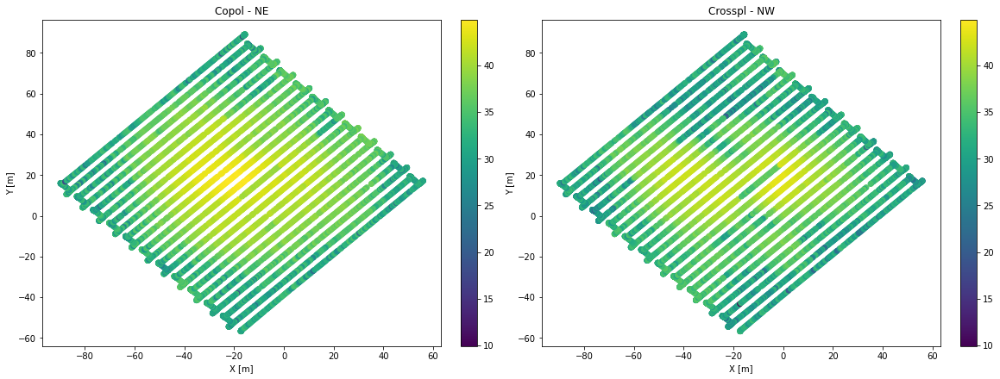

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)



# Compute values once
c1 = 10*np.log10(np.abs(concatdata_ctc.V_cross[tlb:tub, f_ind, 3]))
c2 = 10*np.log10(np.abs(concatdata_ctc.V_cross[tlb:tub, f_ind, 2]))

# Use a common color scale
vmin = min(np.nanmin(c1), np.nanmin(c2))
vmax = max(np.nanmax(c1), np.nanmax(c2))
# Original
sc1 = ax1.scatter(
    concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 0],
    concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 1],
    c=c1,
    vmin=vmin,
    vmax=vmax
)
ax1.set_title("Copol - NE")
ax1.set_xlabel("X [m]")
ax1.set_ylabel("Y [m]")
fig.colorbar(sc1, ax=ax1)

# Time Corrected
sc2 = ax2.scatter(
    concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 0],
    concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 1],
    c=c2,
    vmin=vmin,
    vmax=vmax
)
ax2.set_title("Crosspl - NW")
ax2.set_xlabel("X [m]")
ax2.set_ylabel("Y [m]")
fig.colorbar(sc2, ax=ax2)

plt.show()

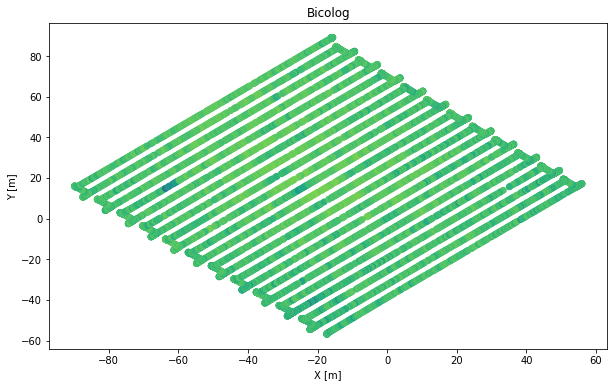

In [28]:
plt.figure(figsize=(10,6))
# Compute values once
c1 = 10*np.log10(np.abs(concatdata_ctc.V_cross[tlb:tub, f_ind, 1]))

sc1 = plt.scatter(
concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 0],
concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 1],
c=c1,
vmin=vmin,
vmax=vmax
)
plt.title("Bicolog")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
fig.colorbar(sc1, ax=ax1)


plt.show()

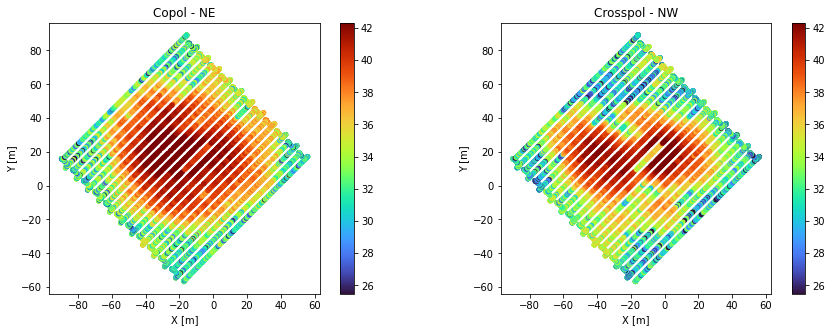

In [30]:
import numpy as np
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12.5, 4.5), constrained_layout=True
)

# Compute values once
c1 = 10*np.log10(np.abs(concatdata_ctc.V_cross[tlb:tub, f_ind, 3]))
c2 = 10*np.log10(np.abs(concatdata_ctc.V_cross[tlb:tub, f_ind, 2]))

# Stack data so both plots use the same percentile-based scaling
all_vals = np.concatenate([c1[np.isfinite(c1)], c2[np.isfinite(c2)]])

vmin = np.percentile(all_vals, 2)
vmax = np.percentile(all_vals, 98)

# Copol - NE
sc1 = ax1.scatter(
    concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 0],
    concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 1],
    c=c1,
    cmap="turbo",
    vmin=vmin,
    vmax=vmax,
    s=18
)

ax1.set_title("Copol - NE")
ax1.set_xlabel("X [m]")
ax1.set_ylabel("Y [m]")
ax1.set_aspect("equal")
fig.colorbar(sc1, ax=ax1)

# Crosspol - NW
sc2 = ax2.scatter(
    concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 0],
    concatdata_ctc.drone_xyz_LC_interp[tlb:tub, 1],
    c=c2,
    cmap="turbo",
    vmin=vmin,
    vmax=vmax,
    s=18
)

ax2.set_title("Crosspol - NW")
ax2.set_xlabel("X [m]")
ax2.set_ylabel("Y [m]")
ax2.set_aspect("equal")
fig.colorbar(sc2, ax=ax2)
fig.savefig("NEgNEp_cop_cross_maps.png", dpi=300, bbox_inches="tight")
plt.show()

Initializing CONCAT CLASS with active traceback using:
  --> /hirax/DNS_freespace/2026_07_GBO/TONE_crs_files/drone_flight9_NEgrid_NEpol_42db_jul2_2000/
  --> Jul-2nd-2026-07-59PM-Flight-Airdata.csv
Creating directory for saving traceback and analysis outputs:
  --> /hirax/DNS_freespace/2026_07_GBO/analysis_outputs/Jul-2nd-2026-07-59PM-Flight-Airdata_drone_flight9_NEgrid_NEpol_42db_jul2_2000_ver_20260922T155921/
Concat initialized without previous config file...
Interpolating drone coordinates for each correlator timestamp:
  --> correlator timestamp axis contains 8225 elements
  --> drone timestamp axis contains 11429 elements
Synchronizing data from correlator and drone:
  --> chans value 3 = Cross 0x3 (fit via np.abs()).
  --> Previous t_delta_dji not found
  --> Calculating via 2DGauss fitting routine:
  --> Applying known t_drone_offset = -245.790s before searching for t_delta_dji


Coarse search:   0%|          | 0/20 [00:00<?, ?it/s]

Fine search:   0%|          | 0/10 [00:00<?, ?it/s]

Applying a time correction of -0.00 seconds using Cross 0x3 fits.
  --> apply_t_delta_dji=False: t_delta_dji = -0.000s found/loaded but NOT applied. This object's drone coordinates still only reflect t_drone_offset = -245.790s. Re-run with apply_t_delta_dji=True to apply it (this will not repeat the search, since t_delta_dji is already cached).
  --> Fitting main beam at t_delta_dji=-0.000s for evaluation/later use (e.g. FWHM vs frequency):
  --> Saved main beam fit parameters: /hirax/DNS_freespace/2026_07_GBO/analysis_outputs/Jul-2nd-2026-07-59PM-Flight-Airdata_drone_flight9_NEgrid_NEpol_42db_jul2_2000_ver_20260922T155921/Jul-2nd-2026-07-59PM-Flight-Airdata_drone_flight9_NEgrid_NEpol_42db_jul2_2000_ver_20260922T155921_Synchronization_MainBeam_Fits.npz
  --> Generating output verification plots (always evaluated at t_delta_dji, regardless of apply_t_delta_dji):
  --> Saving output plot.


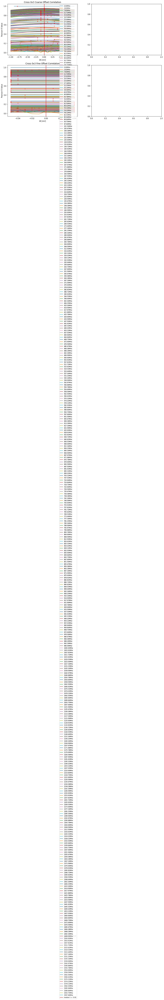

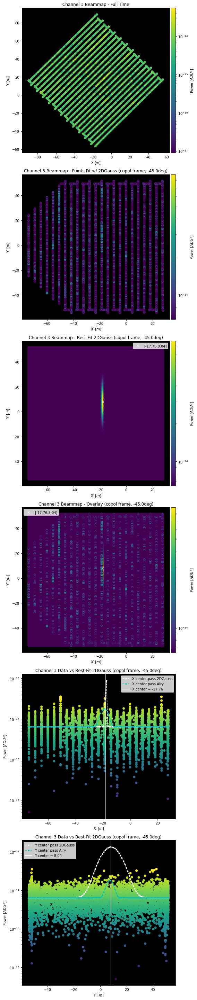

In [10]:
tlb = 4750
tub = 12975

concatdata=concat.CONCAT(
    CORRDATCLASS=corrdata,
    DRONEDATCLASS=dronedata,
    load_yaml=False,
    save_traceback=True,
    output_directory=maindir+'analysis_outputs/',
    t_drone_offset=-245.780-.01,
    t_bounds=[tlb, tub]
)


concatdata.Synchronization_Function(
    inputcorr=corrdata,
    inputdrone=dronedata,

    # Residual search around the applied correction
    coarse_params=[-1.0, 1.0, 0.1],
    fine_params=[-0.05, 0.05, 0.01],

    FMB_coordbounds=[70.0, 70.0, 180.0],
    freqs=np.arange(0,8192,20),
    FMB_ampbound=.999,
    chans=np.array([copolchan]),
    copol_angle_deg=-45 #NW:45.0 or NE:-45.0
)

In [11]:
# --- Cell 1: pickle concatdataf out ---
import pickle
import copy

concatdata_to_save = copy.copy(concatdata)
del concatdata_to_save.prime_origin  # not picklable (local EcefCartesian class)

with open(maindir+'analysis_outputs/concatdata_CHORD0726_NENE.pkl', 'wb') as f:
    pickle.dump(concatdata_to_save, f)

In [12]:
# --- Cell 2: reload it ---
import pickle

with open(maindir+'analysis_outputs/concatdata_CHORD0726_NENE.pkl', 'rb') as f:
    concatdata = pickle.load(f)

print(concatdata.sync_freqs.shape)
print(concatdata.sync_chans)

(410,)
[3]


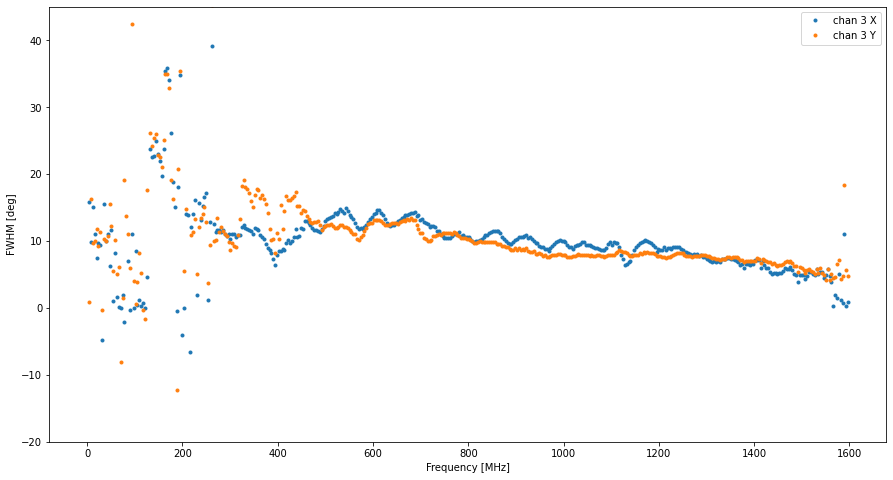

In [13]:
fwhm_const = 2*np.sqrt(2*np.log(2))

freq_MHz = concatdata.freq[concatdata.sync_freqs]
fwhm_x_m = fwhm_const * concatdata.sync_G_popt[:, :, 2]   # xsig -> FWHM [m]
fwhm_y_m = fwhm_const * concatdata.sync_G_popt[:, :, 4]   # ysig -> FWHM [m]

plt.figure(figsize=(15,8))
for i, chan in enumerate(concatdata.sync_chans):
    altitude_m = np.nanmedian(np.abs(concatdata.drone_xyz_per_dish_interp[chan, :, 2]))
    fwhm_x_deg = np.degrees(2*np.arctan((fwhm_x_m[i]/2)/altitude_m))
    fwhm_y_deg = np.degrees(2*np.arctan((fwhm_y_m[i]/2)/altitude_m))
    plt.plot(freq_MHz, fwhm_x_deg, marker='.', linestyle='None', label=f'chan {chan} X')
    plt.plot(freq_MHz, fwhm_y_deg, marker='.', linestyle='None', label=f'chan {chan} Y')
plt.xlabel('Frequency [MHz]')
plt.ylabel('FWHM [deg]')
plt.ylim(-20,45)
plt.legend()
plt.show()

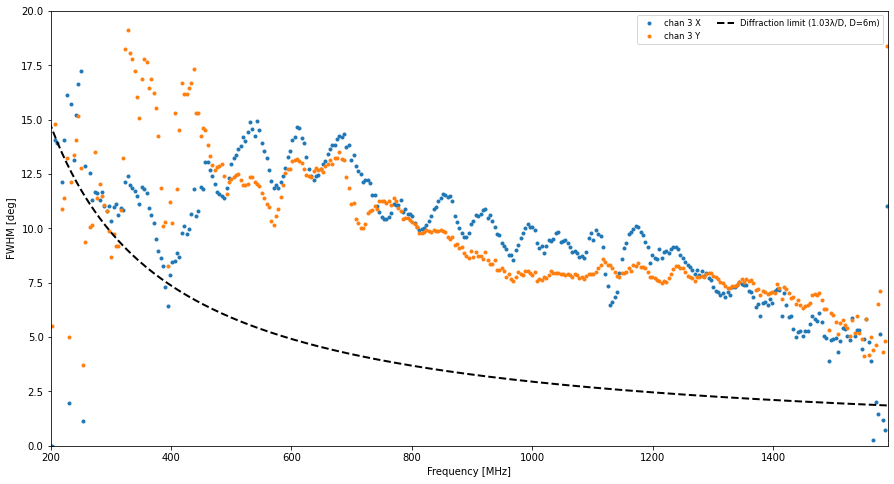

In [14]:
c = 299792458.0  # speed of light, m/s
D = 6.0           # dish diameter, m

valid = freq_MHz > 0          # drop the flagged/zeroed channel
freq_MHz_plot = freq_MHz[valid]

freq_Hz = freq_MHz_plot * 1e6
wavelength_m = c / freq_Hz
diff_limit_deg = np.degrees(1.03 * wavelength_m / D)

plt.figure(figsize=(15,8))
for i, chan in enumerate(concatdata.sync_chans):
    altitude_m = np.nanmedian(np.abs(concatdata.drone_xyz_per_dish_interp[chan, :, 2]))
    fwhm_x_deg = np.degrees(2*np.arctan((fwhm_x_m[i]/2)/altitude_m))
    fwhm_y_deg = np.degrees(2*np.arctan((fwhm_y_m[i]/2)/altitude_m))
    plt.plot(freq_MHz_plot, fwhm_x_deg[valid], marker='.', linestyle='None', label=f'chan {chan} X')
    plt.plot(freq_MHz_plot, fwhm_y_deg[valid], marker='.', linestyle='None', label=f'chan {chan} Y')

plt.plot(freq_MHz_plot, diff_limit_deg, 'k--', linewidth=2, label='Diffraction limit (1.03λ/D, D=6m)')

plt.xlabel('Frequency [MHz]')
plt.ylabel('FWHM [deg]')
plt.legend(fontsize='small', ncol=2)
plt.ylim(0,20)
plt.xlim(200,1590)
plt.show()

Channel index 3 (sync position 0), frequency 550.781 MHz (freq index 2820, sync position 141)
amp=8.865e-12  x0=-24.73  xsig=21.36 (FWHM_x=50.29 m)  y0=2.61  ysig=17.81 (FWHM_y=41.93 m)  bg=9.508e-13
Pearson r for this fit: 0.9202


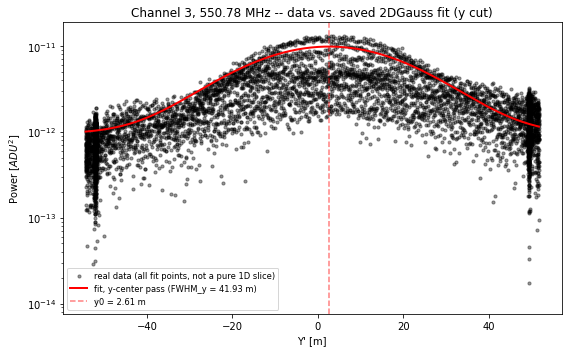

In [22]:
# --- Cell 3: inspect a single frequency's FWHM fit (data vs. fitted Gaussian) ---
import numpy as np

# These three MUST match what you passed into Synchronization_Function, or the
# reconstructed data selection won't match the fit that produced sync_G_popt:
FMB_coordbounds  = [70.0, 70.0, 180.0]
FMB_ampbound     = 0.999
copol_angle_deg  = -45.0

# ---- pick what to look at ----
freq_choice   = 550   # target frequency in MHz; nearest saved sync_freqs entry is used. None = middle of the band.
chan_choice   = None   # a value from concatdata.sync_chans; None = the only/first one
cut_direction = 'y'    # 'x' or 'y' (these are the copol-rotated axes, since copol_angle_deg != 0)

# ---- resolve chan/freq into positions within the saved sync_* arrays ----
if chan_choice is None:
    chan_pos = 0
else:
    chan_pos = int(np.where(concatdata.sync_chans == chan_choice)[0][0])
chan = concatdata.sync_chans[chan_pos]

sync_freq_MHz = concatdata.freq[concatdata.sync_freqs]
freq_pos = len(sync_freq_MHz)//2 if freq_choice is None else int(np.argmin(np.abs(sync_freq_MHz - freq_choice)))
find = concatdata.sync_freqs[freq_pos]

print("Channel index {} (sync position {}), frequency {:.3f} MHz (freq index {}, sync position {})".format(
    chan, chan_pos, concatdata.freq[find], find, freq_pos))

# ---- reproduce Fit_Main_Beam's exact data selection ----
def _axis_bounds(entry):
    if np.isscalar(entry):
        return (-abs(entry), abs(entry))
    lo, hi = entry
    return (lo, hi)

xlo, xhi = _axis_bounds(FMB_coordbounds[0])
ylo, yhi = _axis_bounds(FMB_coordbounds[1])
txcut = concatdata.t_index[(concatdata.drone_xyz_LC_interp[:,0]>xlo)&(concatdata.drone_xyz_LC_interp[:,0]<xhi)]
tycut = concatdata.t_index[(concatdata.drone_xyz_LC_interp[:,1]>ylo)&(concatdata.drone_xyz_LC_interp[:,1]<yhi)]
tzcut = concatdata.t_index[np.abs(concatdata.drone_xyz_LC_interp[:,2])>FMB_coordbounds[2]]
coordcut = np.intersect1d(np.intersect1d(txcut,tycut),tzcut)

V_mag_full = np.abs(concatdata.V[:,find,chan])
tacut = concatdata.t_index[V_mag_full < FMB_ampbound*np.nanmax(V_mag_full)]

try:
    ttcut = np.intersect1d(np.intersect1d(coordcut,tacut), concatdata.inds_on)
except AttributeError:
    ttcut = np.intersect1d(coordcut,tacut)

mbx = concatdata.drone_xyz_LC_interp[ttcut,0]
mby = concatdata.drone_xyz_LC_interp[ttcut,1]
mbV = V_mag_full[ttcut]

# coordbounds selection above stays in the raw NS/EW frame (matches Fit_Main_Beam);
# only NOW do we rotate into the copol frame, same as fu._rotate_xy inside the fit:
mbx, mby = fu._rotate_xy(mbx, mby, copol_angle_deg)

# ---- pull the already-found fit for this (chan, freq) -- no refitting ----
G_popt = concatdata.sync_G_popt[chan_pos, freq_pos]   # [amp, x0, xsig, y0, ysig, c, theta(nan)]
if np.any(np.isnan(G_popt[:6])):
    print("No valid fit was saved for this (channel, frequency) -- nothing to plot.")
else:
    amp, x0, xsig, y0, ysig, c = G_popt[:6]
    fwhm_const = 2.0*np.sqrt(2.0*np.log(2.0))
    fwhm_x, fwhm_y = fwhm_const*xsig, fwhm_const*ysig
    print("amp={:.4g}  x0={:.2f}  xsig={:.2f} (FWHM_x={:.2f} m)  y0={:.2f}  ysig={:.2f} (FWHM_y={:.2f} m)  bg={:.4g}".format(
        amp, x0, xsig, fwhm_x, y0, ysig, fwhm_y, c))
    print("Pearson r for this fit: {:.4f}".format(concatdata.sync_G_PR[chan_pos, freq_pos]))

    fig, ax = subplots(figsize=(8,5))
    axis_label = "X'" if copol_angle_deg != 0.0 else "X"
    if cut_direction == 'x':
        slice_grid = np.linspace(np.nanmin(mbx), np.nanmax(mbx), 200)
        gauss_curve = fu.Gauss_2d_LC_func(G_popt[:6], slice_grid, y0*np.ones(200))
        axis_vals, center, fwhm_label = mbx, x0, "FWHM_x = {:.2f} m".format(fwhm_x)
        ax.set_xlabel("X' [m]" if copol_angle_deg != 0.0 else "X [m]")
    elif cut_direction == 'y':
        slice_grid = np.linspace(np.nanmin(mby), np.nanmax(mby), 200)
        gauss_curve = fu.Gauss_2d_LC_func(G_popt[:6], x0*np.ones(200), slice_grid)
        axis_vals, center, fwhm_label = mby, y0, "FWHM_y = {:.2f} m".format(fwhm_y)
        ax.set_xlabel("Y' [m]" if copol_angle_deg != 0.0 else "Y [m]")
    else:
        raise ValueError("cut_direction must be 'x' or 'y'")

    ax.scatter(axis_vals, mbV, s=10, c='k', alpha=0.4, label='real data (all fit points, not a pure 1D slice)')
    ax.plot(slice_grid, gauss_curve, 'r-', lw=2, label='fit, {}-center pass ({})'.format(cut_direction, fwhm_label))
    ax.axvline(center, color='r', ls='--', alpha=0.5, label='{}0 = {:.2f} m'.format(cut_direction, center))
    ax.set_yscale('log')
    ax.set_ylabel('Power [$ADU^2$]')
    ax.set_title('Channel {}, {:.2f} MHz -- data vs. saved 2DGauss fit ({} cut)'.format(chan, concatdata.freq[find], cut_direction))
    ax.legend(fontsize='small')
    tight_layout()

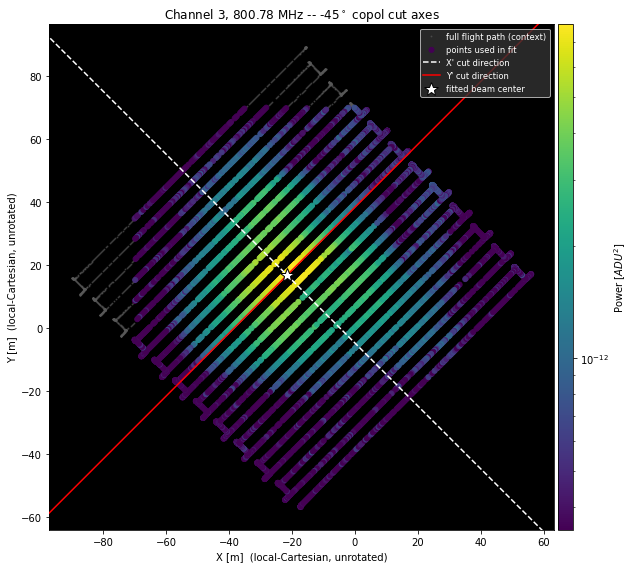

In [15]:
# --- Cell 4: flight path amplitude map with the X'/Y' cut axes overlaid ---
# Styling copied directly from pu.Synchronization_Verification_Plots' own
# "points used in fit" panel: no cmap override, LogNorm(), clim clipped to
# the local (model, data) range -- that clim clipping, not the colormap, is
# what keeps those panels from washing out.
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import LogNorm

FMB_coordbounds  = [70.0, 70.0, 180.0]
FMB_ampbound     = 0.999
copol_angle_deg  = -45.0

freq_choice = None
chan_choice = None

if chan_choice is None:
    chan_pos = 0
else:
    chan_pos = int(np.where(concatdata.sync_chans == chan_choice)[0][0])
chan = concatdata.sync_chans[chan_pos]

sync_freq_MHz = concatdata.freq[concatdata.sync_freqs]
freq_pos = len(sync_freq_MHz)//2 if freq_choice is None else int(np.argmin(np.abs(sync_freq_MHz - freq_choice)))
find = concatdata.sync_freqs[freq_pos]
G_popt = concatdata.sync_G_popt[chan_pos, freq_pos]

tzcut = concatdata.t_index[np.abs(concatdata.drone_xyz_LC_interp[:,2])>FMB_coordbounds[2]]
try:
    tbig = np.intersect1d(tzcut, concatdata.inds_on)
except AttributeError:
    tbig = tzcut

def _axis_bounds(entry):
    if np.isscalar(entry):
        return (-abs(entry), abs(entry))
    lo, hi = entry
    return (lo, hi)
xlo, xhi = _axis_bounds(FMB_coordbounds[0])
ylo, yhi = _axis_bounds(FMB_coordbounds[1])
txcut = concatdata.t_index[(concatdata.drone_xyz_LC_interp[:,0]>xlo)&(concatdata.drone_xyz_LC_interp[:,0]<xhi)]
tycut = concatdata.t_index[(concatdata.drone_xyz_LC_interp[:,1]>ylo)&(concatdata.drone_xyz_LC_interp[:,1]<yhi)]
coordcut = np.intersect1d(np.intersect1d(txcut,tycut),tzcut)
V_mag_full = np.abs(concatdata.V[:,find,chan])
tacut = concatdata.t_index[V_mag_full < FMB_ampbound*np.nanmax(V_mag_full)]
try:
    ttcut = np.intersect1d(np.intersect1d(coordcut,tacut), concatdata.inds_on)
except AttributeError:
    ttcut = np.intersect1d(coordcut,tacut)

# kept in the RAW (unrotated) frame here, unlike Cell 3, so the flight path
# geometry on this plot matches the true physical track:
mbx = concatdata.drone_xyz_LC_interp[ttcut,0]
mby = concatdata.drone_xyz_LC_interp[ttcut,1]
mbV = V_mag_full[ttcut]

if np.any(np.isnan(G_popt[:6])):
    print("No valid fit was saved for this (channel, frequency) -- nothing to plot.")
else:
    x0_raw, y0_raw = fu._rotate_xy(G_popt[1], G_popt[3], -copol_angle_deg)
    ux, uy = fu._rotate_xy(1.0, 0.0, -copol_angle_deg)
    vx, vy = fu._rotate_xy(0.0, 1.0, -copol_angle_deg)

    # Evaluate the fitted model on a raw-frame grid by rotating each grid
    # point INTO the fit's native (copol) frame first -- G_popt's xsig/ysig
    # are axis-aligned there, not in the raw frame:
    simx=np.outer(np.linspace(np.nanmin(mbx),np.nanmax(mbx),100),np.ones(100)).flatten()
    simy=np.outer(np.ones(100),np.linspace(np.nanmin(mby),np.nanmax(mby),100)).flatten()
    simx_rot,simy_rot=fu._rotate_xy(simx,simy,copol_angle_deg)
    simV=fu.Gauss_2d_LC_func(G_popt[:6],simx_rot,simy_rot)

    fig,ax=subplots(figsize=(9,8))
    ax.set_facecolor('k')
    ax.plot(concatdata.drone_xyz_LC_interp[tbig,0], concatdata.drone_xyz_LC_interp[tbig,1],
            '.', color='0.35', ms=2, alpha=0.5, zorder=1, label='full flight path (context)')
    im=ax.scatter(mbx, mby, c=mbV, norm=LogNorm(), s=25, zorder=2, label='points used in fit')
    im.set_clim(np.nanmax((np.nanmin(simV),np.nanmin(mbV))), np.nanmax((np.nanmax(simV),np.nanmax(mbV))))

    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    span = max(xlim[1]-xlim[0], ylim[1]-ylim[0])
    ax.plot([x0_raw-span*ux, x0_raw+span*ux], [y0_raw-span*uy, y0_raw+span*uy], color='white', ls='--', lw=1.5, zorder=3, label="X' cut direction")
    ax.plot([x0_raw-span*vx, x0_raw+span*vx], [y0_raw-span*vy, y0_raw+span*vy], color='red', ls='-', lw=1.5, zorder=3, label="Y' cut direction")
    ax.plot(x0_raw, y0_raw, marker='*', color='white', mec='k', ms=14, ls='none', zorder=4, label='fitted beam center')
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect('equal')

    ax.set_xlabel('X [m]  (local-Cartesian, unrotated)')
    ax.set_ylabel('Y [m]  (local-Cartesian, unrotated)')
    ax.set_title("Channel {}, {:.2f} MHz -- {:.0f}$^\\circ$ copol cut axes".format(chan, concatdata.freq[find], copol_angle_deg))
    divider=make_axes_locatable(ax)
    cax=divider.append_axes("right", size="3%", pad=0.05)
    cbar=fig.colorbar(im,cax=cax)
    cbar.set_label('Power [$ADU^2$]')
    ax.legend(loc='upper right', fontsize='small', facecolor='0.2', labelcolor='w')
    tight_layout()